In [49]:
# zamana bağlı verilerin tahmini yapılır. gelecekteki durumunu tahmin edebileceğimiz modeller.
#facebook-prophet
 #FBProphet ile Zamana Bağlı Yapay Zeka Tahminler Bitcoin,Google,Dolar Hisse

In [2]:
!pip install fbprophet

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'fbprophet' when getting requirements to build wheel


In [3]:
!pip install yfinance

In [5]:
from prophet import Prophet
import yfinance as yf

In [17]:
df=yf.download("BTC-USD","2015-01-1","2024-04-06")
df=df[["Close"]]
df=df.reset_index()
df.columns=["ds","y"]

/tmp/ipykernel_1964/3568558750.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df=yf.download("BTC-USD","2015-01-1","2024-04-06")
[*********************100%***********************]  1 of 1 completed


In [18]:
df.head(3)

,ds,y
0,2015-01-01,314.248993
1,2015-01-02,315.032013
2,2015-01-03,281.082001


In [22]:
model = Prophet()
model.fit(df)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [36]:
gelecek = model.make_future_dataframe(720) #100.günü bilmek için 99.günü bilmek gerekli, 99 için 98.günü bilmek gerekli. yani o zamana kadarki tüm tarihleri tahmin etmem gerekiyor bunun dateframeni oluşturacağım.
#default'u day . periods= parametresi ile değiştirebilirsin.

In [37]:
tahmin=model.predict(gelecek)

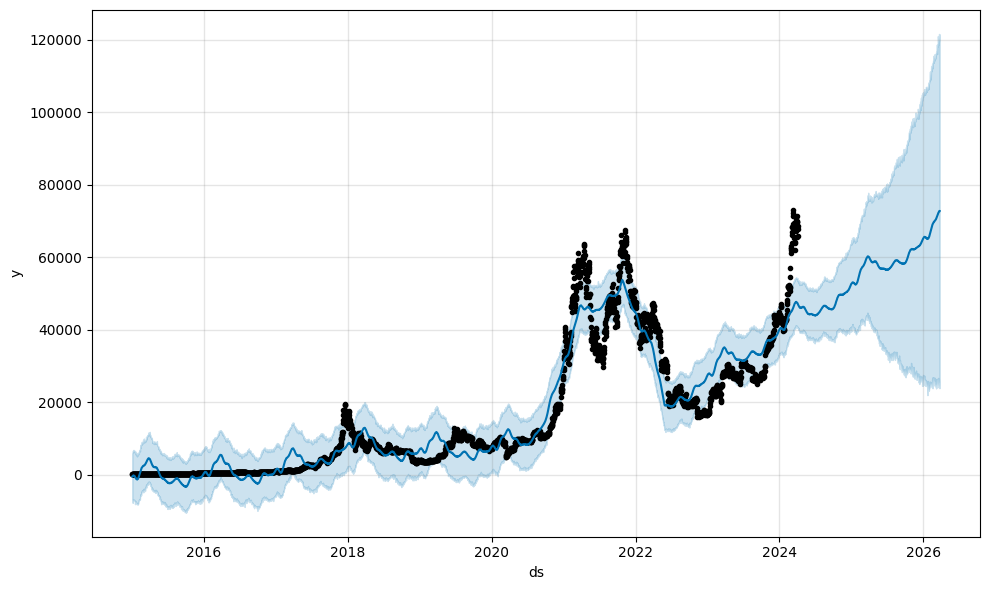

In [38]:
model.plot(tahmin);

In [43]:
df_g=yf.download("GOOG","2019-01-01","2026-04-26")
df_g=df_g[["Close"]]
df_g=df_g.reset_index()
df_g.columns=["ds","y"]
model_g = Prophet()
model_g.fit(df_g)
gelecek_g = model.make_future_dataframe(720)

/tmp/ipykernel_1964/2612281797.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_g=yf.download("GOOG","2019-01-01","2026-04-26")
[*********************100%***********************]  1 of 1 completed
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [44]:
tahmin_g=model_g.predict(gelecek_g)

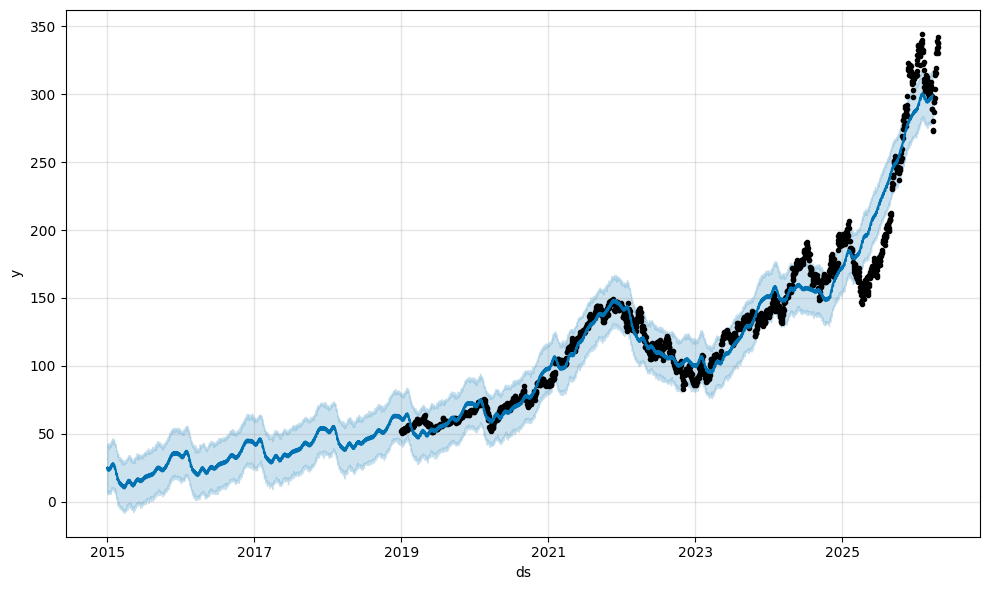

In [45]:
model_g.plot(tahmin_g);

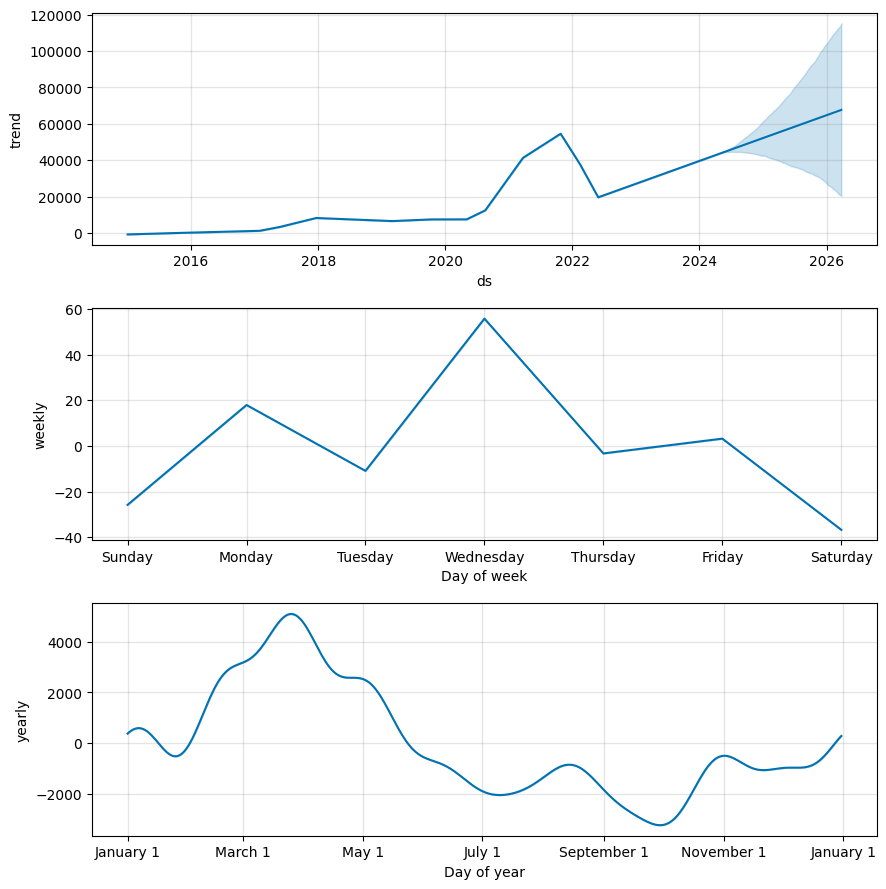

In [48]:
model.plot_components(tahmin);